In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
import numpy as np
import matplotlib.pyplot as plt
from network import *
from GNAR import *
from GNARBoost import *
from tqdm.notebook import tqdm
from time import time
import pickle
import json

# Simulation

In [2]:
def sim_nar(p,coefs1,coefs2,length=200,burn_in=100):
    T = burn_in+length
    ts = np.zeros(T)
    ts[:p] = np.random.normal(size=p)
    for t in range(p,T):
        ts[t] = np.dot(ts[t-p:t],coefs1)+np.dot(ts[t-p:t]*coefs2,ts[t-p:t][::-1])+np.random.normal()
    return ts[burn_in:]

In [3]:
def NLAGNAR_sim(f, network, alpha_order, beta_order, intercept,global_intercept,error_cov_mat, length, burn_in = 100):
    vts = np.zeros((length+burn_in+alpha_order,network.size))
    vts[:alpha_order] = norm(loc=0).rvs(size=(alpha_order,network.size))
    g = GNAR(alpha_order,beta_order,intercept,global_intercept)
    g.network = network
    for t in range(alpha_order,length+burn_in+alpha_order):
        vts[t] = f(g.transformVTS(vts[t-g.alpha_order:t+1])).reshape(-1) + multivariate_normal(
                cov=error_cov_mat).rvs(1)
    return vts[burn_in+alpha_order:]

In [4]:
def f_lin(X):
    return X[:,0]/3 + X[:,1]/3 + X[:,5]/3
def f_cos_sin(X):
    return np.cos(X[:,0]/3) + np.sin(X[:,2]/2) + np.cos(X[:,4]+X[:,5])
def f_exp(X):
    return 0.5*np.exp(-X[:,0]**2)*X[:,1] + 0.4*np.exp(-X[:,3]**2)*X[:,5]
def f_frac(X):
    return 0.4*(np.abs(X[:,0]))/(1/3+X[:,2]**2) + 0.4*(np.abs(X[:,4]))/(1/2+X[:,5]**2)

In [5]:
n8_7=Network({0:[1],1:[0],2:[4],3:[4],4:[2],5:[0,1],6:[3],7:[6]},symmetry=True)

In [6]:
np.random.seed(1)
vts_sim_lin = NLAGNAR_sim(f_lin, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000)
vts_sim_lin_test = NLAGNAR_sim(f_lin, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000)

In [7]:
np.random.seed(1)
vts_sim_cos_sin = NLAGNAR_sim(f_cos_sin, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000)
vts_sim_cos_sin_test = NLAGNAR_sim(f_cos_sin, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000)

In [8]:
np.random.seed(1)
vts_sim_exp = NLAGNAR_sim(f_exp, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000)
vts_sim_exp_test = NLAGNAR_sim(f_exp, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000)

In [9]:
np.random.seed(1)
vts_sim_frac = NLAGNAR_sim(f_frac, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000,burn_in=0)
vts_sim_frac_test = NLAGNAR_sim(f_frac, n8_7, 3,[1,1,1],False,True,np.eye(8)*0.1,1000)

### P1

In [10]:
p=3
H=1
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[20],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=50, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.CV(n8_7,vts_sim_lin,seed=1)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

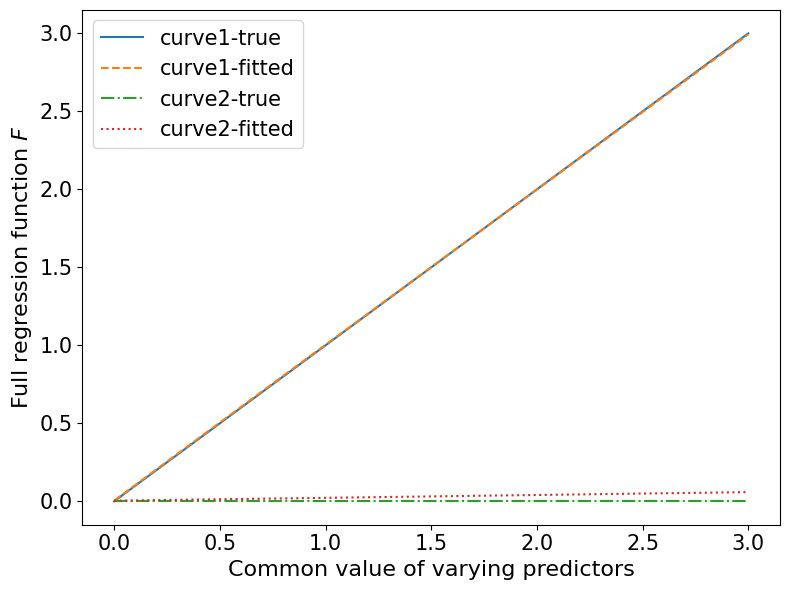

In [11]:
plt.figure(figsize=(8,6))

X = np.tile(np.linspace(0,3,1000).reshape(-1,1),(1,6))
x = np.linspace(0,3,1000)

plt.plot(x, f_lin(X), label="curve1-true", linestyle="-")
plt.plot(x, gnarb.evaluate(X,0), label="curve1-fitted", linestyle="--")

X[:,[0,1,5]] = 0

plt.plot(x, f_lin(X), label="curve2-true", linestyle="-.")
plt.plot(x, gnarb.evaluate(X,0), label="curve2-fitted", linestyle=":")

plt.xlabel("Common value of varying predictors", fontsize=16)
plt.ylabel(r"Full regression function $F$", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

In [12]:
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
M = gnarb.I[0]
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[20],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=25, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.fit(n8_7,vts_sim_lin)
sses_pred = gnarb.predict_validate(vts_sim_lin_test)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

5
802.250902407025


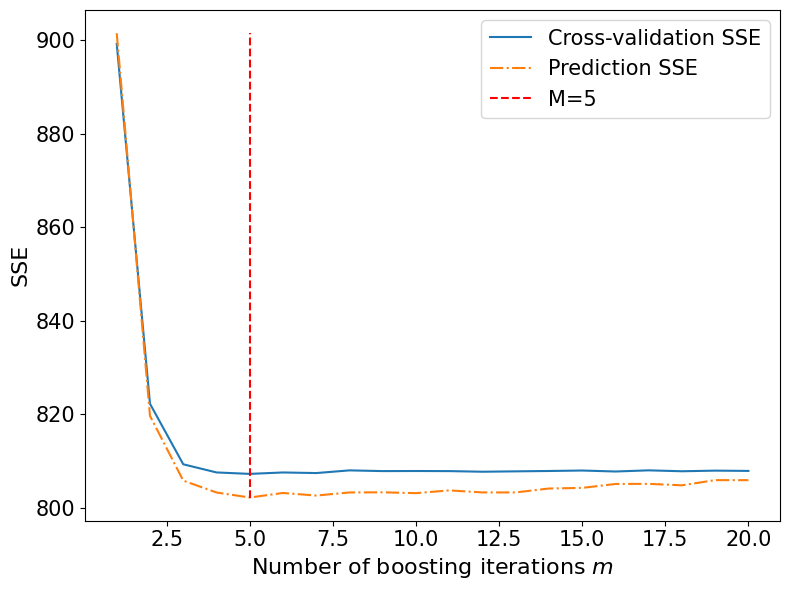

In [13]:
print(M)
print(sses_pred[0][M-1])

plt.figure(figsize=(8,6))
plt.plot(range(1,gnarb.I[0]+1), sses_CV[:], label="Cross-validation SSE", linestyle="-")
plt.plot(range(1,gnarb.I[0]+1), sses_pred[0][:], label="Prediction SSE", linestyle="-.")
plt.vlines(M, min((np.min(sses_CV),np.min(sses_pred[0]))), max((np.max(sses_CV),np.max(sses_pred[0]))), label="M="+str(M), colors="red", linestyle="dashed")

plt.xlabel("Number of boosting iterations $m$", fontsize=16)
plt.ylabel("SSE", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

### P2

In [15]:
p=3
H=1
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[500],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=25, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.CV(n8_7,vts_sim_cos_sin,seed=1)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/388 [00:00<?, ?it/s]

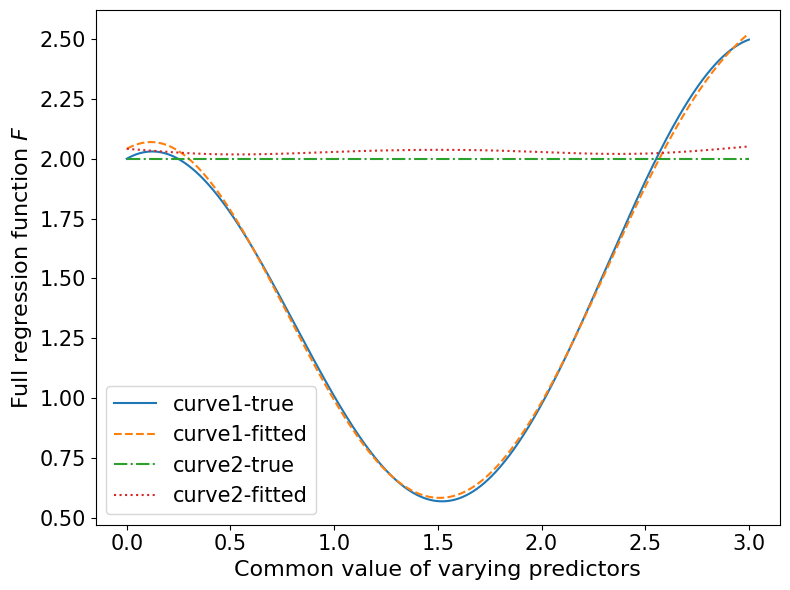

In [18]:
plt.figure(figsize=(8,6))
X = np.tile(np.linspace(0,3,1000).reshape(-1,1),(1,6))
x = np.linspace(0,3,1000)

plt.plot(x,f_cos_sin(X),label="curve1-true", linestyle="-")
plt.plot(x,gnarb.evaluate(X,0),label="curve1-fitted", linestyle="--")

X[:,[0,2,4,5]] = 0

plt.plot(x,f_cos_sin(X),label="curve2-true", linestyle="-.")
plt.plot(x,gnarb.evaluate(X,0),label="curve2-fitted", linestyle=":")

plt.xlabel("Common value of varying predictors", fontsize=16)
plt.ylabel(r"Full regression function $F$", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

In [30]:
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
M = gnarb.I[0]
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[500],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=25, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.fit(n8_7,vts_sim_cos_sin)
sses_pred = gnarb.predict_validate(vts_sim_cos_sin_test)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

388
810.2008215128949


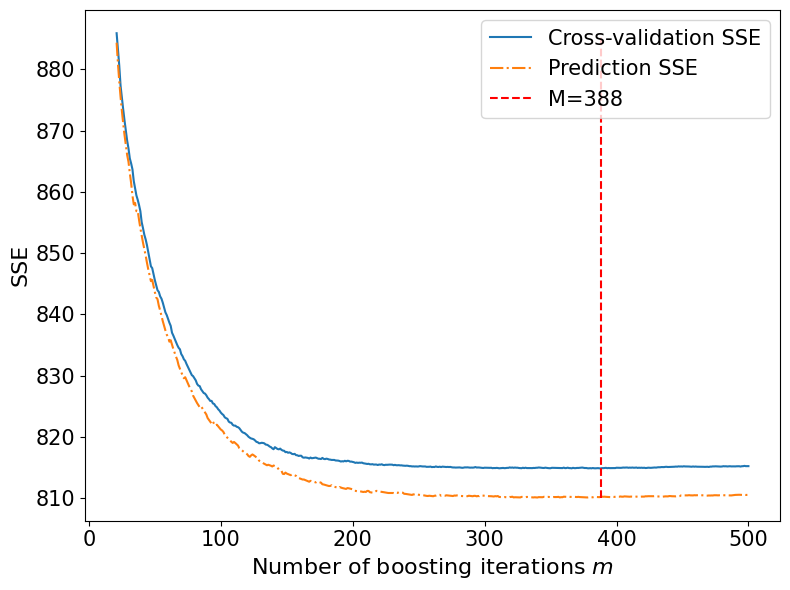

In [31]:
print(M)
print(sses_pred[0][M-1])

plt.figure(figsize=(8,6))
plt.plot(range(21,gnarb.I[0]+1), sses_CV[20:], label="Cross-validation SSE", linestyle="-")
plt.plot(range(21,gnarb.I[0]+1), sses_pred[0][20:], label="Prediction SSE", linestyle="-.")
plt.vlines(M, min((np.min(sses_CV[20:]),np.min(sses_pred[0][20:]))), max((np.max(sses_CV[20:]),np.max(sses_pred[0][20:]))), label="M="+str(M), colors="red", linestyle="dashed")

plt.xlabel("Number of boosting iterations $m$", fontsize=16)
plt.ylabel("SSE", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

### P3

In [36]:
p=3
H=1
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[200],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=25, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.CV(n8_7,vts_sim_exp,seed=1)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/48 [00:00<?, ?it/s]

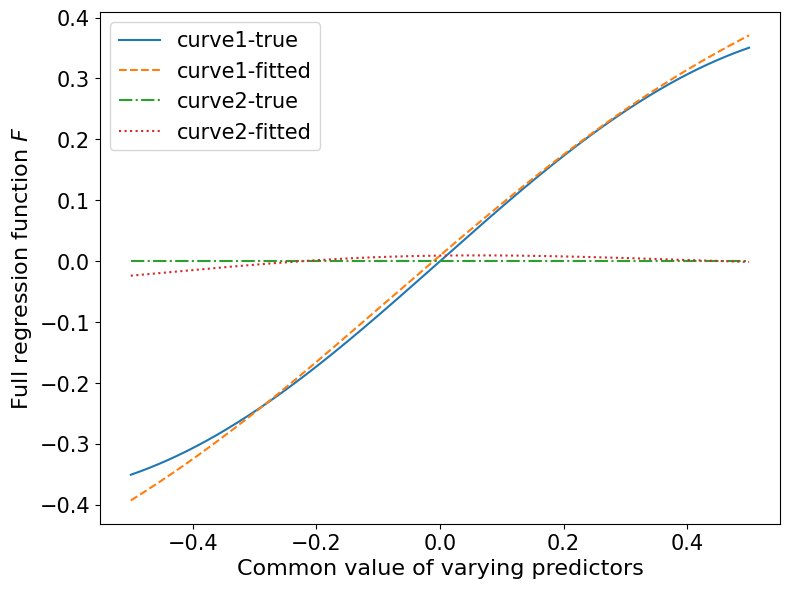

In [37]:
plt.figure(figsize=(8,6))
X = np.tile(np.linspace(-0.5,.5,1000).reshape(-1,1),(1,6))
x = np.linspace(-0.5,0.5,1000)

plt.plot(x,f_exp(X),label="curve1-true", linestyle="-")
plt.plot(x,gnarb.evaluate(X,0),label="curve1-fitted", linestyle="--")

X[:,[0,1,3,5]] = 0

plt.plot(x,f_exp(X),label="curve2-true", linestyle="-.")
plt.plot(x,gnarb.evaluate(X,0),label="curve2-fitted", linestyle=":")

plt.xlabel("Common value of varying predictors", fontsize=16)
plt.ylabel(r"Full regression function $F$", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

In [38]:
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
M = gnarb.I[0]
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[200],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=25, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.fit(n8_7,vts_sim_exp)
sses_pred = gnarb.predict_validate(vts_sim_exp_test)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

48
808.8082006595182


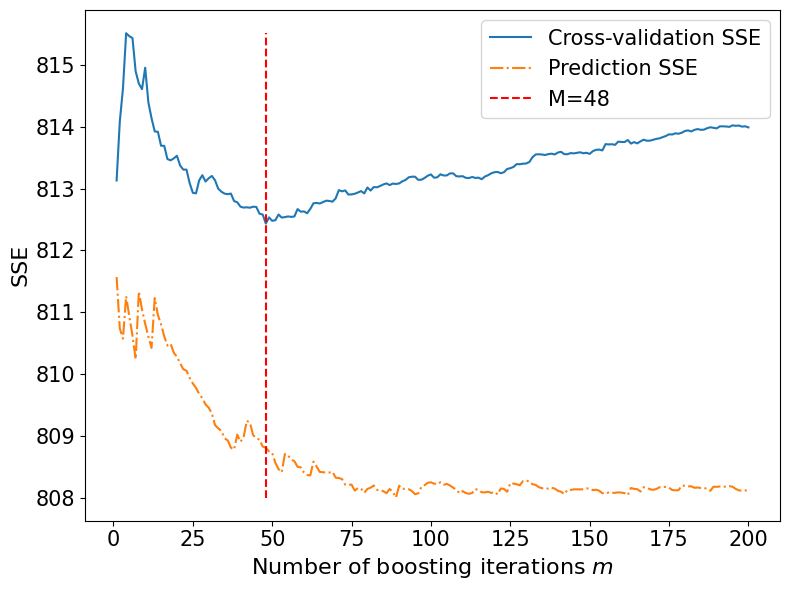

In [39]:
print(M)
print(sses_pred[0][M-1])

plt.figure(figsize=(8,6))
plt.plot(range(1,gnarb.I[0]+1), sses_CV[:], label="Cross-validation SSE", linestyle="-")
plt.plot(range(1,gnarb.I[0]+1), sses_pred[0][:], label="Prediction SSE", linestyle="-.")
plt.vlines(M, min((np.min(sses_CV),np.min(sses_pred[0]))), max((np.max(sses_CV),np.max(sses_pred[0]))), label="M="+str(M), colors="red", linestyle="dashed")

plt.xlabel("Number of boosting iterations $m$", fontsize=16)
plt.ylabel("SSE", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

### P 4

In [40]:
p=3
H=1
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[2000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=20, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.CV(n8_7,vts_sim_frac,seed=1)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/1839 [00:00<?, ?it/s]

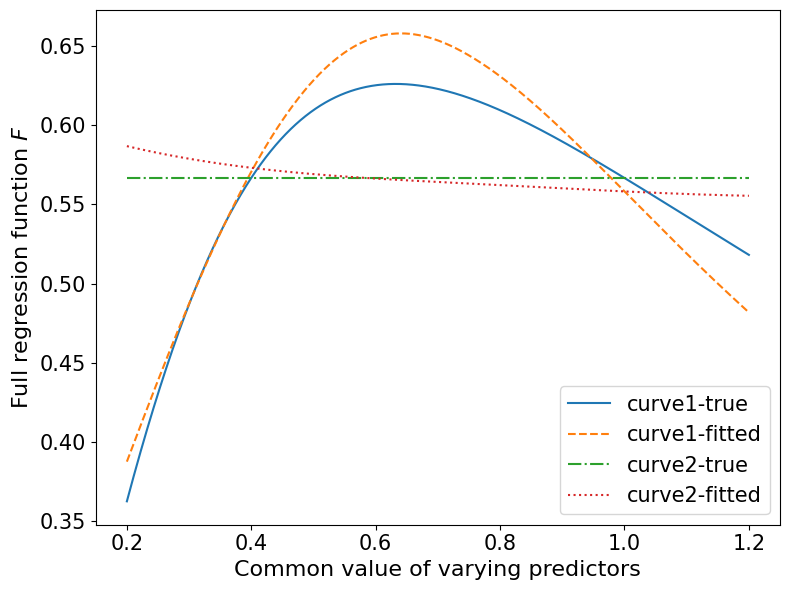

In [41]:
plt.figure(figsize=(8,6))
X = np.tile(np.linspace(0.2,1.2,1000).reshape(-1,1),(1,6))
x = np.linspace(0.2,1.2,1000)

plt.plot(x,f_frac(X),label="curve1-true", linestyle="-")
plt.plot(x,gnarb.evaluate(X,0),label="curve1-fitted", linestyle="--")

X[:,[0,2,4,5]] = 1

plt.plot(x,f_frac(X),label="curve2-true", linestyle="-.")
plt.plot(x,gnarb.evaluate(X,0),label="curve2-fitted", linestyle=":")

plt.xlabel("Common value of varying predictors", fontsize=16)
plt.ylabel(r"Full regression function $F$", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

In [42]:
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
M = gnarb.I[0]
gnarb = GNARBoost(p,[1 for _ in range(p)],intercept=False,H=H,I=[2000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=20, smooth_2d=500, shrink=1., cross_term=True,base_gnar=False,clamp=False,aggregate=False)
gnarb.fit(n8_7,vts_sim_frac)
sses_pred = gnarb.predict_validate(vts_sim_frac_test)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

1839
809.7940829959209


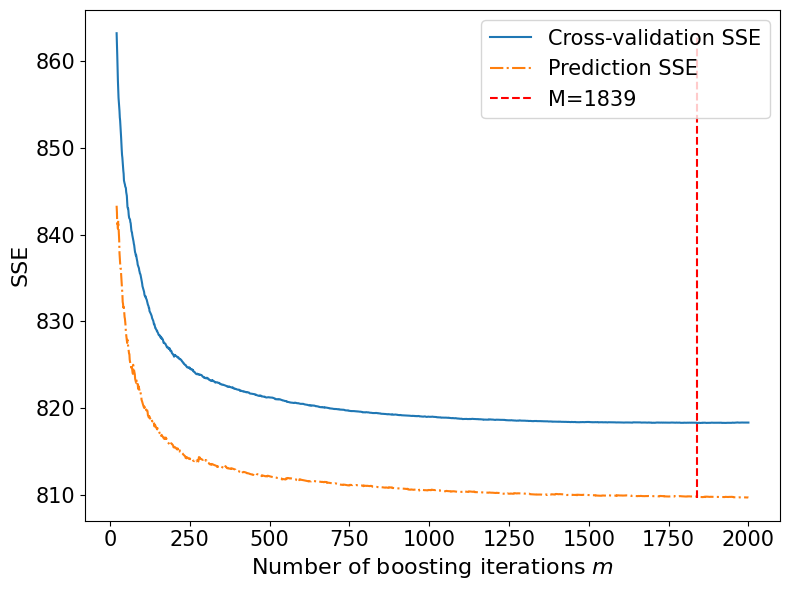

In [43]:
print(M)
print(sses_pred[0][M-1])

plt.figure(figsize=(8,6))
plt.plot(range(21,gnarb.I[0]+1), sses_CV[20:], label="Cross-validation SSE", linestyle="-")
plt.plot(range(21,gnarb.I[0]+1), sses_pred[0][20:], label="Prediction SSE", linestyle="-.")
plt.vlines(M, min((np.min(sses_CV[20:]),np.min(sses_pred[0][20:]))), max((np.max(sses_CV[20:]),np.max(sses_pred[0][20:]))), label="M="+str(M), colors="red", linestyle="dashed")

plt.xlabel("Number of boosting iterations $m$", fontsize=16)
plt.ylabel("SSE", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

# London Traffic Application

## Preprocessing

In [20]:
from london_traffic import *
london_vts = np.nan_to_num(london_vts, nan=0.0)

In [21]:
def get_edges_knn(dist_mat,k=3):
    N = len(dist_mat)
    dists= {}
    edges= {}
    for i in range(N):
        inds = np.argpartition(dist_mat[i], k)[:k+1].tolist()
        inds.remove(i)
        edges[i] = inds
        dists[i] = dist_mat[i][inds]
    return edges,dists 

def aggregate(vts,agg_factor):
    T,N = vts.shape
    T_new = T // agg_factor  # number of full hours
    vts_trim = vts[:T_new*agg_factor, :]  # shape (T_new*12, N)
    vts_reshaped =vts_trim.reshape(T_new, agg_factor, N)
    vts_agg = vts_reshaped.mean(axis=1)
    return vts_agg

In [22]:
def deseason_seasonal_mean_2d(x, period, axis=0):
    """
    Deseason by subtracting the mean seasonal cycle.
    """
    x = np.asarray(x, dtype=float)
    if x.ndim != 2:
        raise ValueError(f"x must be 2D, got shape {x.shape}")

    p = int(period)
    if p < 2:
        raise ValueError("period must be >= 2")

    # Put time on axis 0: shape (T, N)
    if axis == 1:
        xT = x.T
    elif axis == 0:
        xT = x
    else:
        raise ValueError("axis must be 0 (time rows) or 1 (time cols)")

    T, N = xT.shape
    seasonalT = np.zeros_like(xT)

    for r in range(p):
        idx = np.arange(r, T, p)             # time indices with phase r
        # mean across those times, separately for each series (column)
        m = np.nanmean(xT[idx, :], axis=0)   # shape (N,)
        seasonalT[idx, :] = m                # broadcast to (len(idx), N)

    x_deseasonT = xT - seasonalT + np.mean(xT,axis=0)

    # Put back to original orientation
    if axis == 1:
        return x_deseasonT.T, seasonalT.T
    return x_deseasonT, seasonalT

In [23]:
london_vts_h = aggregate(london_vts,4)
london_vts_hd, seasonal = deseason_seasonal_mean_2d(london_vts_h,24)

## Select the network and GNAR order

In [12]:
for k in range(1,10):
    edges,dists = get_edges_knn(london_dist_mat,k)
    london_network = Network(edges,dists,gamma=1.)
    p = 5
    s=3
    alpha_opt = [0 for _ in range(p)]
    beta_opt = [0 for _ in range(p)]
    sses_opt = [np.inf]
    for i in tqdm(range((s+1)*p)):  
        sses = []
        for j in range(p):
            if alpha_opt[j] == 0:
                alpha = deepcopy(alpha_opt)
                alpha[j] = 1
                g = GNAR(alpha,beta_opt,intercept=True,global_alpha=True)
                sse = g.CV(london_network,london_vts_hd[:1440],5,0,random=False,use_ls=True)
                sses.append(sse)
            else:
                sses.append(sses_opt[-1])
        for j in range(p):
            if beta_opt[j] < s:
                beta = deepcopy(beta_opt)
                beta[j] +=1
                g = GNAR(alpha_opt,beta,intercept=True,global_alpha=True)
                sse = g.CV(london_network,london_vts_hd[:1440],5,0,random=False,use_ls=True)
                sses.append(sse)
            else:
                sses.append(sses_opt[-1])
        if np.min(sses) < sses_opt[-1]:
            j_opt = np.argmin(sses)
            sses_opt.append(np.min(sses))
            if j_opt < p:
                alpha_opt[j_opt] = 1
            else:
                beta_opt[j_opt-p] += 1
        else:
            break
    sses_opt = sses_opt[1:]
    print(k,sses_opt)
    print(alpha_opt)
    print(beta_opt)

  0%|          | 0/20 [00:00<?, ?it/s]

1 [2764.224676475281, 2568.198699009283, 2545.6784824267943, 2518.3890564761477, 2512.927949190742, 2502.4499949879355, 2502.3412054250666]
[1, 1, 0, 0, 0]
[3, 2, 0, 0, 0]


  0%|          | 0/20 [00:00<?, ?it/s]

2 [2764.224676475281, 2568.198699009283, 2530.6123590013967, 2488.189890209086, 2484.2999053191947, 2474.3285595649104, 2473.449245045941, 2472.4842982967302]
[1, 1, 0, 0, 0]
[3, 3, 0, 0, 0]


  0%|          | 0/20 [00:00<?, ?it/s]

3 [2764.224676475281, 2568.198699009283, 2527.3731800988166, 2480.1768289750717, 2471.285032403603, 2470.4879588929575, 2469.7221720859256, 2469.5413552991745, 2469.254031158477]
[1, 1, 0, 0, 0]
[3, 2, 2, 0, 0]


... (8 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

8 [2764.224676475281, 2568.198699009283, 2524.951220225639, 2475.8410215817903, 2470.9176270718112, 2445.6429940716016, 2444.7873696252286]
[1, 1, 0, 0, 0]
[3, 2, 0, 0, 0]


  0%|          | 0/20 [00:00<?, ?it/s]

9 [2764.224676475281, 2568.198699009283, 2524.805343631444, 2475.1826314216373, 2472.360691817279, 2450.540858738462]
[1, 1, 0, 0, 0]
[2, 2, 0, 0, 0]


In [25]:
edges,dists = get_edges_knn(london_dist_mat,7)
london_network = Network(edges,dists,gamma=1.)
london_network_0 = Network(edges,dists,gamma=0.)

## Other Models

### GNAR

In [26]:
p= 2
g = GNAR(p,[2 for _ in range(p)],intercept=True,global_alpha=True)
g.fit(london_network,london_vts_hd[:1440])
sse_gnar = g.validate(london_vts_hd[1440-p:1680])
print(sse_gnar)

32168742.133454576


#### Try a different p as a sensitivity analysis

In [29]:
p= 4
g = GNAR(p,[2 for _ in range(p)],intercept=True,global_alpha=True)
g.fit(london_network,london_vts_hd[:1440])
sse_gnar = g.validate(london_vts_hd[1440-p:1680])
print(sse_gnar)

32184612.63266801


In [30]:
32168742.133454576/32184612.63266801

0.9995068917126775

### AR

In [23]:
sses = []
for p in [1,2,3,4,5]:
    g = GNAR(p,[0 for _ in range(p)],intercept=True,global_alpha=False)
    sse = g.CV(london_network,london_vts_hd[:1440],5,0)
    print(sse)
    sses.append(sse)
print("best_p = " + str([1,2,3,4,5][np.argmin(sses)]))

2752.5619602037295
2600.0983005635712
2620.473761427557
2615.7632843330293
2601.8875357021884
best_p = 2


In [19]:
p=2
g = GNAR(p,[0 for _ in range(p)],intercept=True,global_alpha=False)
g.fit(london_network,london_vts_hd[:1440])
sse_gnar = g.validate(london_vts_hd[1440-p:1680])
print(sse_gnar)

33952920.3625581


### NAR

In [25]:
sses = []
for p in [1,2,3,4,5]:
    g = GNAR(p,[1 for _ in range(p)],intercept=True,global_alpha=True)
    sse = g.CV(london_network_0,london_vts_hd[:1440],5,0)
    print(sse)
    sses.append(sse)
print("best_p = " + str([1,2,3,4,5][np.argmin(sses)]))

2742.566496524381
2445.149860919212
2445.2704918766376
2430.8449098455626
2438.112459907695
best_p = 4


In [18]:
p=4
g = GNAR(p,[1 for _ in range(p)],intercept=True,global_alpha=True)
g.fit(london_network_0,london_vts_hd[:1440])
sse_gnar = g.validate(london_vts_hd[1440-p:1680])
print(sse_gnar)

32666029.198139228


#### Try a different p as a sensitivity analysis

In [31]:
p=2
g = GNAR(p,[1 for _ in range(p)],intercept=True,global_alpha=True)
g.fit(london_network_0,london_vts_hd[:1440])
sse_gnar = g.validate(london_vts_hd[1440-p:1680])
print(sse_gnar)

32697800.480657585


### VARLasso

In [62]:
sses_vl = []
for p in [1,2,3,4,5]:
    for alpha in np.linspace(1,10,10)+2*(p-1):
        vl = VARLasso(p,alpha,fit_intercept=True,gpu=True)
        sse = vl.CV(london_vts_hd[:1440],5,seed=0)
        print(p,alpha,sse)
        sses_vl.append(sse)

1 1.0 2135.4194441599975
1 2.0 2131.6820861694227
1 3.0 2128.8255406533663
1 4.0 2129.0256343209603
1 5.0 2129.6982258836215
1 6.0 2135.873018770426
1 7.0 2137.088077205433
1 8.0 2142.3478811622026
1 9.0 2148.249420217215
1 10.0 2153.0277805084884
2 3.0 1972.8358706013237
2 4.0 1967.761048784832
2 5.0 1964.8045569107746
2 6.0 1963.8617595365147
2 7.0 1964.0581251439949
2 8.0 1964.6950385520743
2 9.0 1966.6307078214554
2 10.0 1968.5431113624009
2 11.0 1970.1587221406198
2 12.0 1971.4418944653435
3 5.0 1967.401005582797
3 6.0 1965.2960849673693
3 7.0 1965.3345342017924
3 8.0 1964.1958915172586
3 9.0 1964.8551253370433
3 10.0 1964.9652055904207
3 11.0 1965.7775132279614
3 12.0 1966.2140416074783
3 13.0 1967.6206815501769
3 14.0 1968.772862003671
4 7.0 1963.9768261206325
4 8.0 1961.8284174060655
4 9.0 1960.9425449684736
4 10.0 1960.5065329125896
4 11.0 1959.3855497070335
4 12.0 1960.1029287861184
4 13.0 1960.9543208024888
4 14.0 1961.352644873283
4 15.0 1962.166177321883
4 16.0 1962.449031

In [28]:
sses_vl = []
for p in [1,2,3,4,5]:
    for alpha in np.linspace(1,10,10)+2*(p-1):
        vl = VARLasso(p,alpha,fit_intercept=True,gpu=True)
        sse = vl.CV(london_vts_hd[:1440],5,seed=0)
        print(p,alpha,sse)
        sses_vl.append(sse)

1 1.0 2135.4194441599975
1 2.0 2131.6820861694227
1 3.0 2128.8255406533663
1 4.0 2129.0256343209603
1 5.0 2129.6982258836215
1 6.0 2135.873018770426
1 7.0 2137.088077205433
1 8.0 2142.3478811622026
1 9.0 2148.249420217215
1 10.0 2153.0277805084884
2 3.0 1972.8358706013237
2 4.0 1967.761048784832
2 5.0 1964.8045569107746
2 6.0 1963.8617595365147
2 7.0 1964.0581251439949
2 8.0 1964.6950385520743
2 9.0 1966.6307078214554
2 10.0 1968.5431113624009
2 11.0 1970.1587221406198
2 12.0 1971.4418944653435
3 5.0 1967.401005582797
3 6.0 1965.2960849673693
3 7.0 1965.3345342017924
3 8.0 1964.1958915172586
3 9.0 1964.8551253370433
3 10.0 1964.9652055904207
3 11.0 1965.7775132279614
3 12.0 1966.2140416074783
3 13.0 1967.6206815501769
3 14.0 1968.772862003671
4 7.0 1963.9768261206325
4 8.0 1961.8284174060655
4 9.0 1960.9425449684736
4 10.0 1960.5065329125896
4 11.0 1959.3855497070335
4 12.0 1960.1029287861184
4 13.0 1960.9543208024888
4 14.0 1961.352644873283
4 15.0 1962.166177321883
4 16.0 1962.449031

In [75]:
print("best_p = " + str([1,2,3,4,5][np.argmin(sses_vl)//10]))
print("best_lambda = " + str((np.linspace(1,10,10)+2*([1,2,3,4,5][np.argmin(sses_vl)//10]-1))[np.argmin(sses_vl)%10]))

best_p = 4
best_lambda = 11.0


In [14]:
vl = VARLasso(4,11,fit_intercept=True,gpu=True)
vl.fit(london_vts_hd[:1440])
vl.validate(london_vts_hd[1440-p:1680])

32837018.790257327

### VAR

In [26]:
sses = []
for p in [1,2,3,4,5]:
    vl = VARLasso(p,0,fit_intercept=True,gpu=True)
    sse = vl.CV(london_vts_hd[:1440],5,seed=0)
    sses.append(sse)
print("best_p = " + str([1,2,3,4,5][np.argmin(sses)]))

best_p = 2


In [13]:
vl = VARLasso(2,0,fit_intercept=True)
vl.fit(london_vts_hd[:1440])
vl.validate(london_vts_hd[1440-p:1680])

39950658.07979477

## GNAR Boosting

### Check the edof

In [31]:
for smooth_params in [[2.6,240],[13,500],[30,730],[60,1200]]:
    p=2
    H=1
    gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[10],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                      smooth_1d=smooth_params[0], smooth_2d=smooth_params[1], shrink=1, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
    gnarb.fit(london_network,london_vts_hd[:1440])
    print(smooth_params)
    for i in range(10): 
        V = gnarb.spline_opts[0][i].V
        P = gnarb.spline_opts[0][i].P
        
        # 10x10 Gram matrix (keep it small)
        G = (V.T @ V)
        G = G.toarray() if sp.issparse(G) else np.asarray(G)
        
        # penalty (10x10)
        P = P.toarray() if sp.issparse(P) else np.asarray(P)
        
        M = G + P
        
        # edof = tr(M^{-1} G) without forming M^{-1}
        edof = float(np.trace(np.linalg.solve(M, G)))
        
        print(edof, gnarb.inds_opts[0][i])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

[2.6, 240]
6.976580704688075 0
6.899183947378408 [1, 3]
6.900727905607608 [0, 4]
6.968341235887564 1
7.1634931848476375 [0, 2]
7.163455426851991 [3, 5]
7.199028167093511 [2, 3]
7.174414106869872 [0, 5]
6.899183947378408 [1, 3]
7.1634931848476375 [0, 2]


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

[13, 500]
5.986803004710677 0
5.840106105221362 [1, 3]
5.8398500890751235 [0, 4]
5.840106105221362 [1, 3]
6.060757668104955 [0, 2]
5.945811605787913 [1, 5]
6.060757668104955 [0, 2]
6.060701318357265 [3, 5]
6.077145046761472 [2, 3]
6.064638745286834 [0, 5]


... (2 outputs left out)

[30, 730]
5.465525229543899 0
5.409607218211355 [1, 3]
5.408938979899998 [0, 4]
5.409607218211355 [1, 3]
5.465525229543899 0
5.506637334800797 [1, 5]
5.62156198290901 [2, 3]
5.610584422129882 [3, 5]
5.62156198290901 [2, 3]
5.610584422129882 [3, 5]


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

[60, 1200]
5.008396701405349 0
4.961470577011672 [1, 3]
4.9606306034419765 [0, 4]
4.961470577011672 [1, 3]
5.008396701405349 0
5.044859224505116 [1, 5]
5.139166624606213 [2, 3]
5.132566295402674 [3, 5]
5.139166624606213 [2, 3]
5.132566295402674 [3, 5]


### Choose hyperparams

#### edof ~= 7

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/747 [00:00<?, ?it/s]

29394407.800955504 747
140891673.09428835


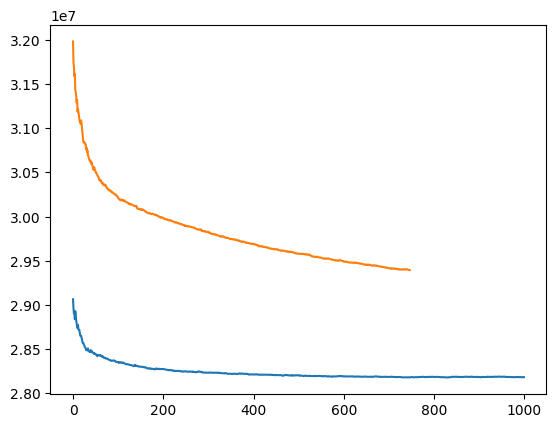

In [64]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[1000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=2.6, smooth_2d=240, shrink=1, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/1999 [00:00<?, ?it/s]

29321280.922954794 1999
140827382.7632124


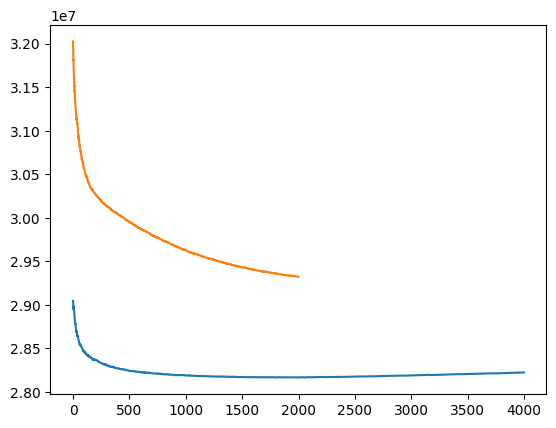

In [65]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[4000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=2.6, smooth_2d=240, shrink=.5, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1177 [00:00<?, ?it/s]

29348438.844536882 1177
140856822.7046423


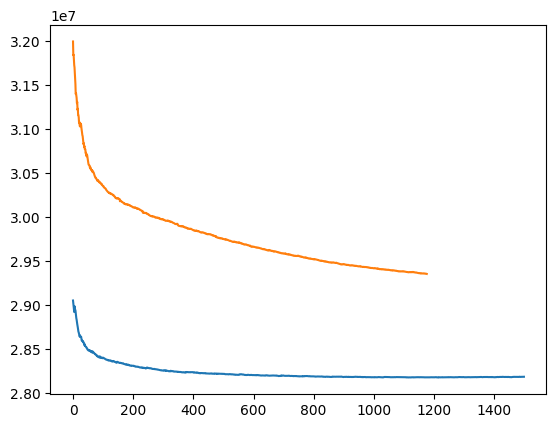

In [66]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[1500],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=2.6, smooth_2d=240, shrink=.75, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

#### edof ~= 6

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/1609 [00:00<?, ?it/s]

29360283.563527986 1609
140593915.39463493


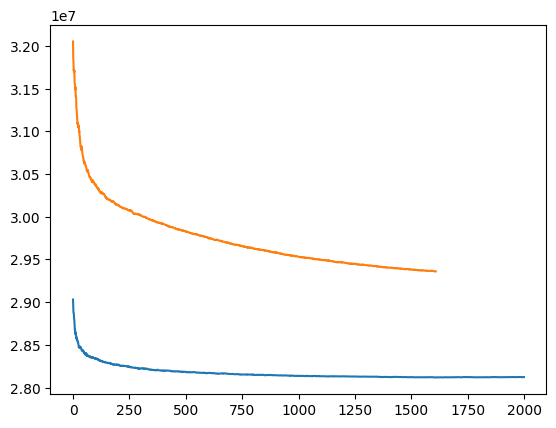

In [67]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[2000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=13, smooth_2d=500, shrink=1, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/3430 [00:00<?, ?it/s]

29347951.734537676 3430
140548334.56658092


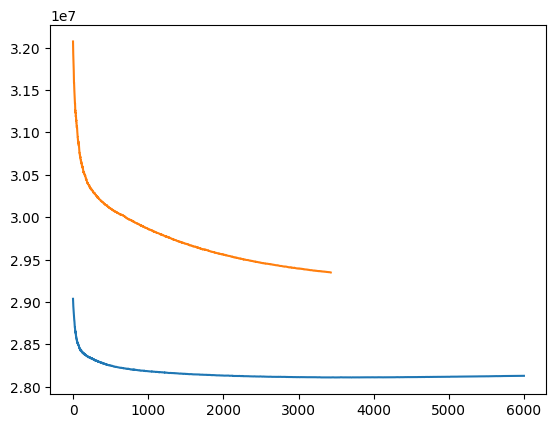

In [68]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=13, smooth_2d=500, shrink=.5, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/3500 [00:00<?, ?it/s]

  0%|          | 0/3500 [00:00<?, ?it/s]

  0%|          | 0/3500 [00:00<?, ?it/s]

  0%|          | 0/3500 [00:00<?, ?it/s]

  0%|          | 0/3500 [00:00<?, ?it/s]

  0%|          | 0/2322 [00:00<?, ?it/s]

29341204.666578244 2322
140571266.40591845


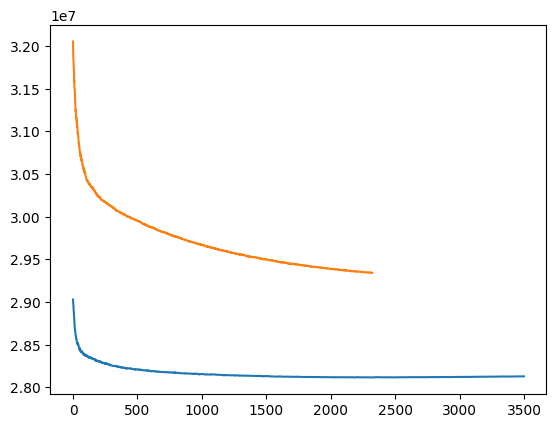

In [69]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[3500],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=13, smooth_2d=500, shrink=.75, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

#### edof ~= 5.5

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/2060 [00:00<?, ?it/s]

29410484.246488757 2060
140538078.45112634


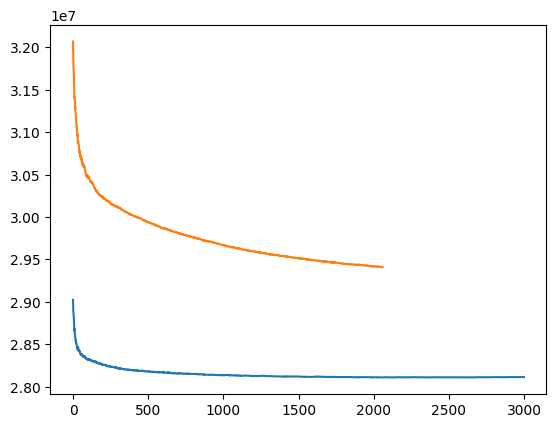

In [70]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[3000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=30, smooth_2d=730, shrink=1, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/5235 [00:00<?, ?it/s]

29342592.428770706 5235
140489645.89562854


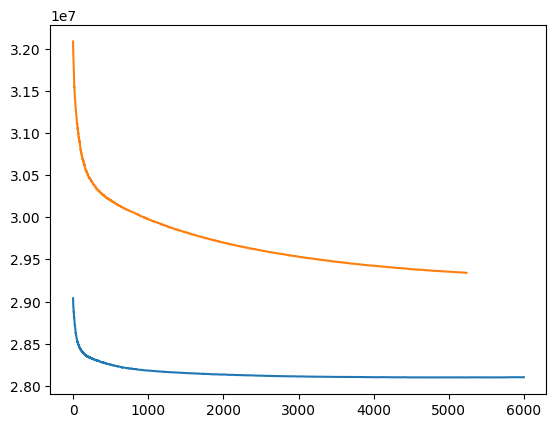

In [11]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=30, smooth_2d=730, shrink=.5, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/3453 [00:00<?, ?it/s]

29351675.294538677 3453
140511027.5703853


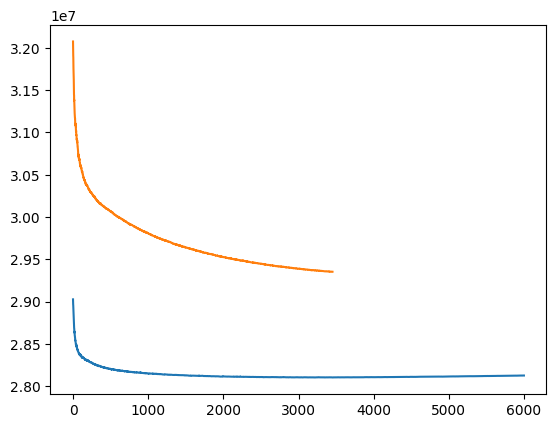

In [12]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=30, smooth_2d=730, shrink=.75, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

#### edof ~= 5

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/2802 [00:00<?, ?it/s]

29471518.38918488 2802
140557567.41073602


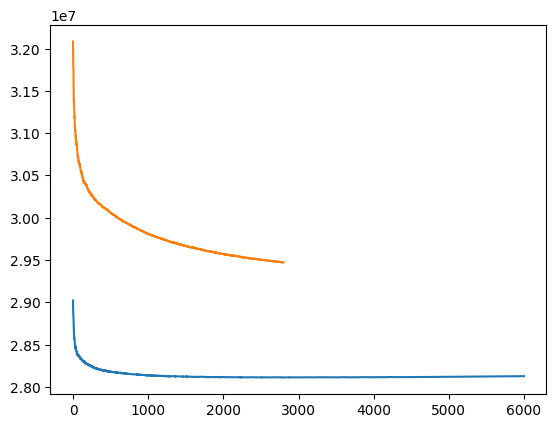

In [11]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=60, smooth_2d=1200, shrink=1, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/5951 [00:00<?, ?it/s]

29454572.785383493 5951
140511884.27510783


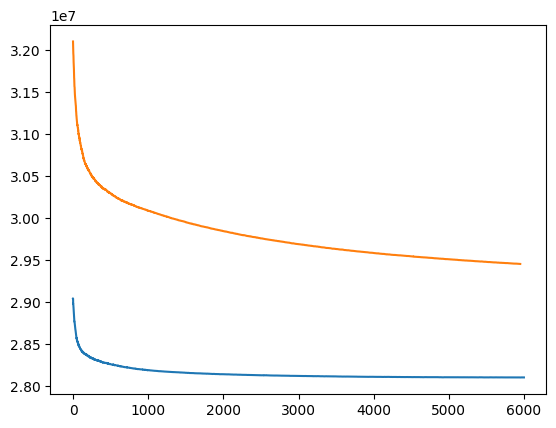

In [12]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=60, smooth_2d=1200, shrink=.5, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/4518 [00:00<?, ?it/s]

29419505.154414058 4518
140530803.56183612


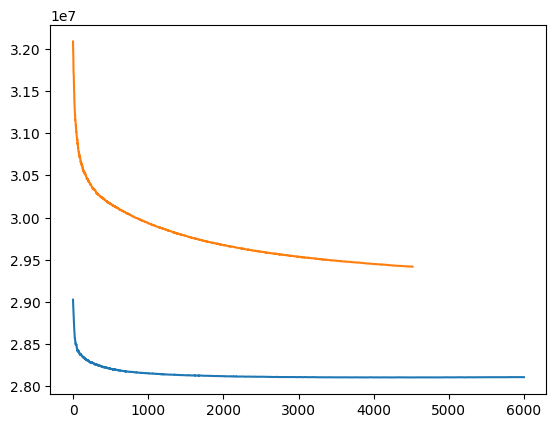

In [13]:
p=2
H=1
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=60, smooth_2d=1200, shrink=.75, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True)
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])
print(sses_pred[0][-1], gnarb.I_eff[0])
sses_CV = gnarb.sse_vals_H[0].sum(axis=0)
print(np.min(sses_CV))
M = gnarb.I_eff[0]
plt.plot(sses_CV[:]/5)
plt.plot(sses_pred[0][:])

### Use the best set of hyperparams 30, 730, 0.5

In [ ]:
p=2
H=1
gnarb_cv = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=30, smooth_2d=730, shrink=.5, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb_cv.CV(london_network,london_vts_hd[:1440],random=True,full_random=False,seed=0,base_refit=True,last_fit=False)
sses_CV = gnarb_cv.sse_vals_H[0].sum(axis=0)
M = gnarb_cv.I_eff[0]
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[6000],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=30, smooth_2d=730, shrink=.5, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.fit(london_network,london_vts_hd[:1440])
sses_pred = gnarb.predict_validate(london_vts_hd[1440-p:1680])

5235
29342592.428770706


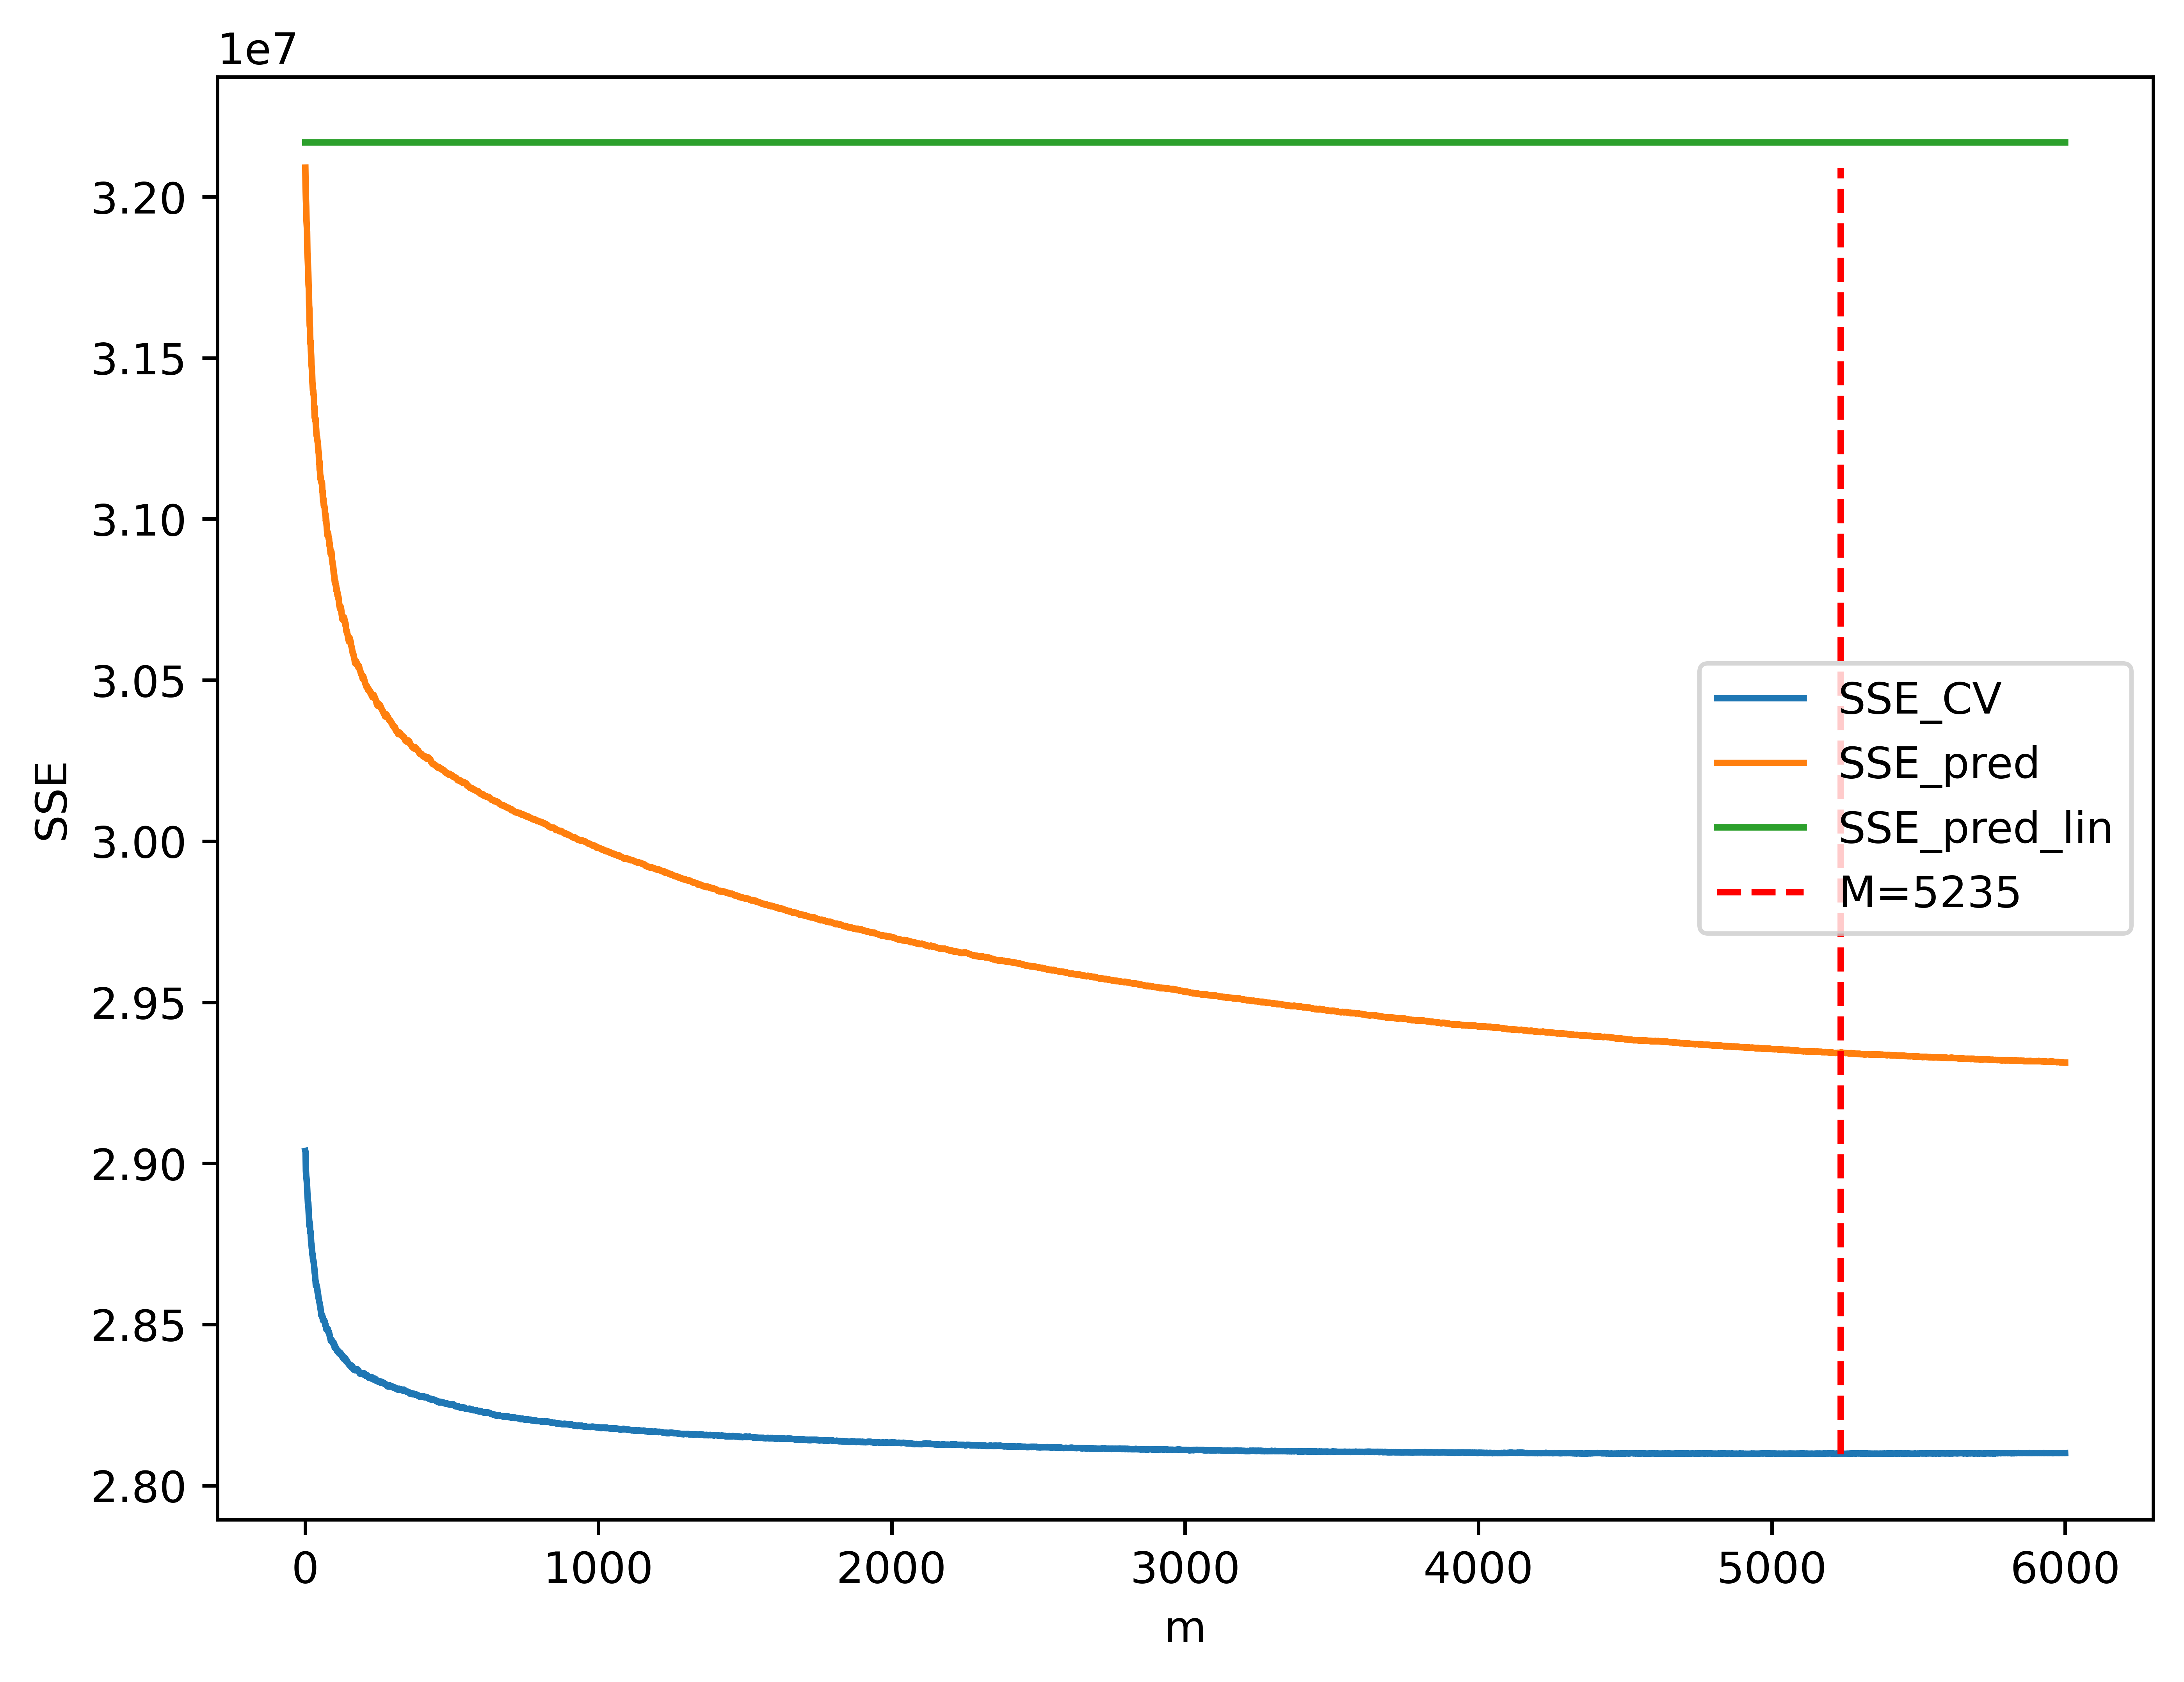

In [17]:
print(M)
print(sses_pred[0][M-1])
plt.figure(figsize=(8,6),dpi=800)
plt.plot(range(1,6000+1),sses_CV[:]/5,label="SSE_CV")
plt.plot(range(1,6000+1),sses_pred[0][:6000],label="SSE_pred")
plt.plot(range(1,6000+1),[sse_gnar for i in range(6000)],label="SSE_pred_lin")
plt.vlines(M,
           min((np.min(sses_CV[:]/5),np.min(sses_pred[0][:]))),
           max((np.max(sses_CV[:]/5),np.max(sses_pred[0][:]))),
           label="M="+str(M),colors="red",linestyle="dashed")
#plt.title("London Traffic")
plt.xlabel("m")
plt.ylabel("SSE")
plt.legend()
plt.show()

In [49]:
H=1
p=2
gnarb = GNARBoost(p,[2 for _ in range(p)],intercept=True,H=H,I=[5235],recursive_pred=False,k=3,n_splines_1d=10,n_splines_2d=10,
                  smooth_1d=30, smooth_2d=730, shrink=.5, cross_term=True,base_gnar=True,clamp=False,aggregate=False)
gnarb.fit(london_network,london_vts_hd[:1440])

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/5235 [00:00<?, ?it/s]

### Plot the fitted function

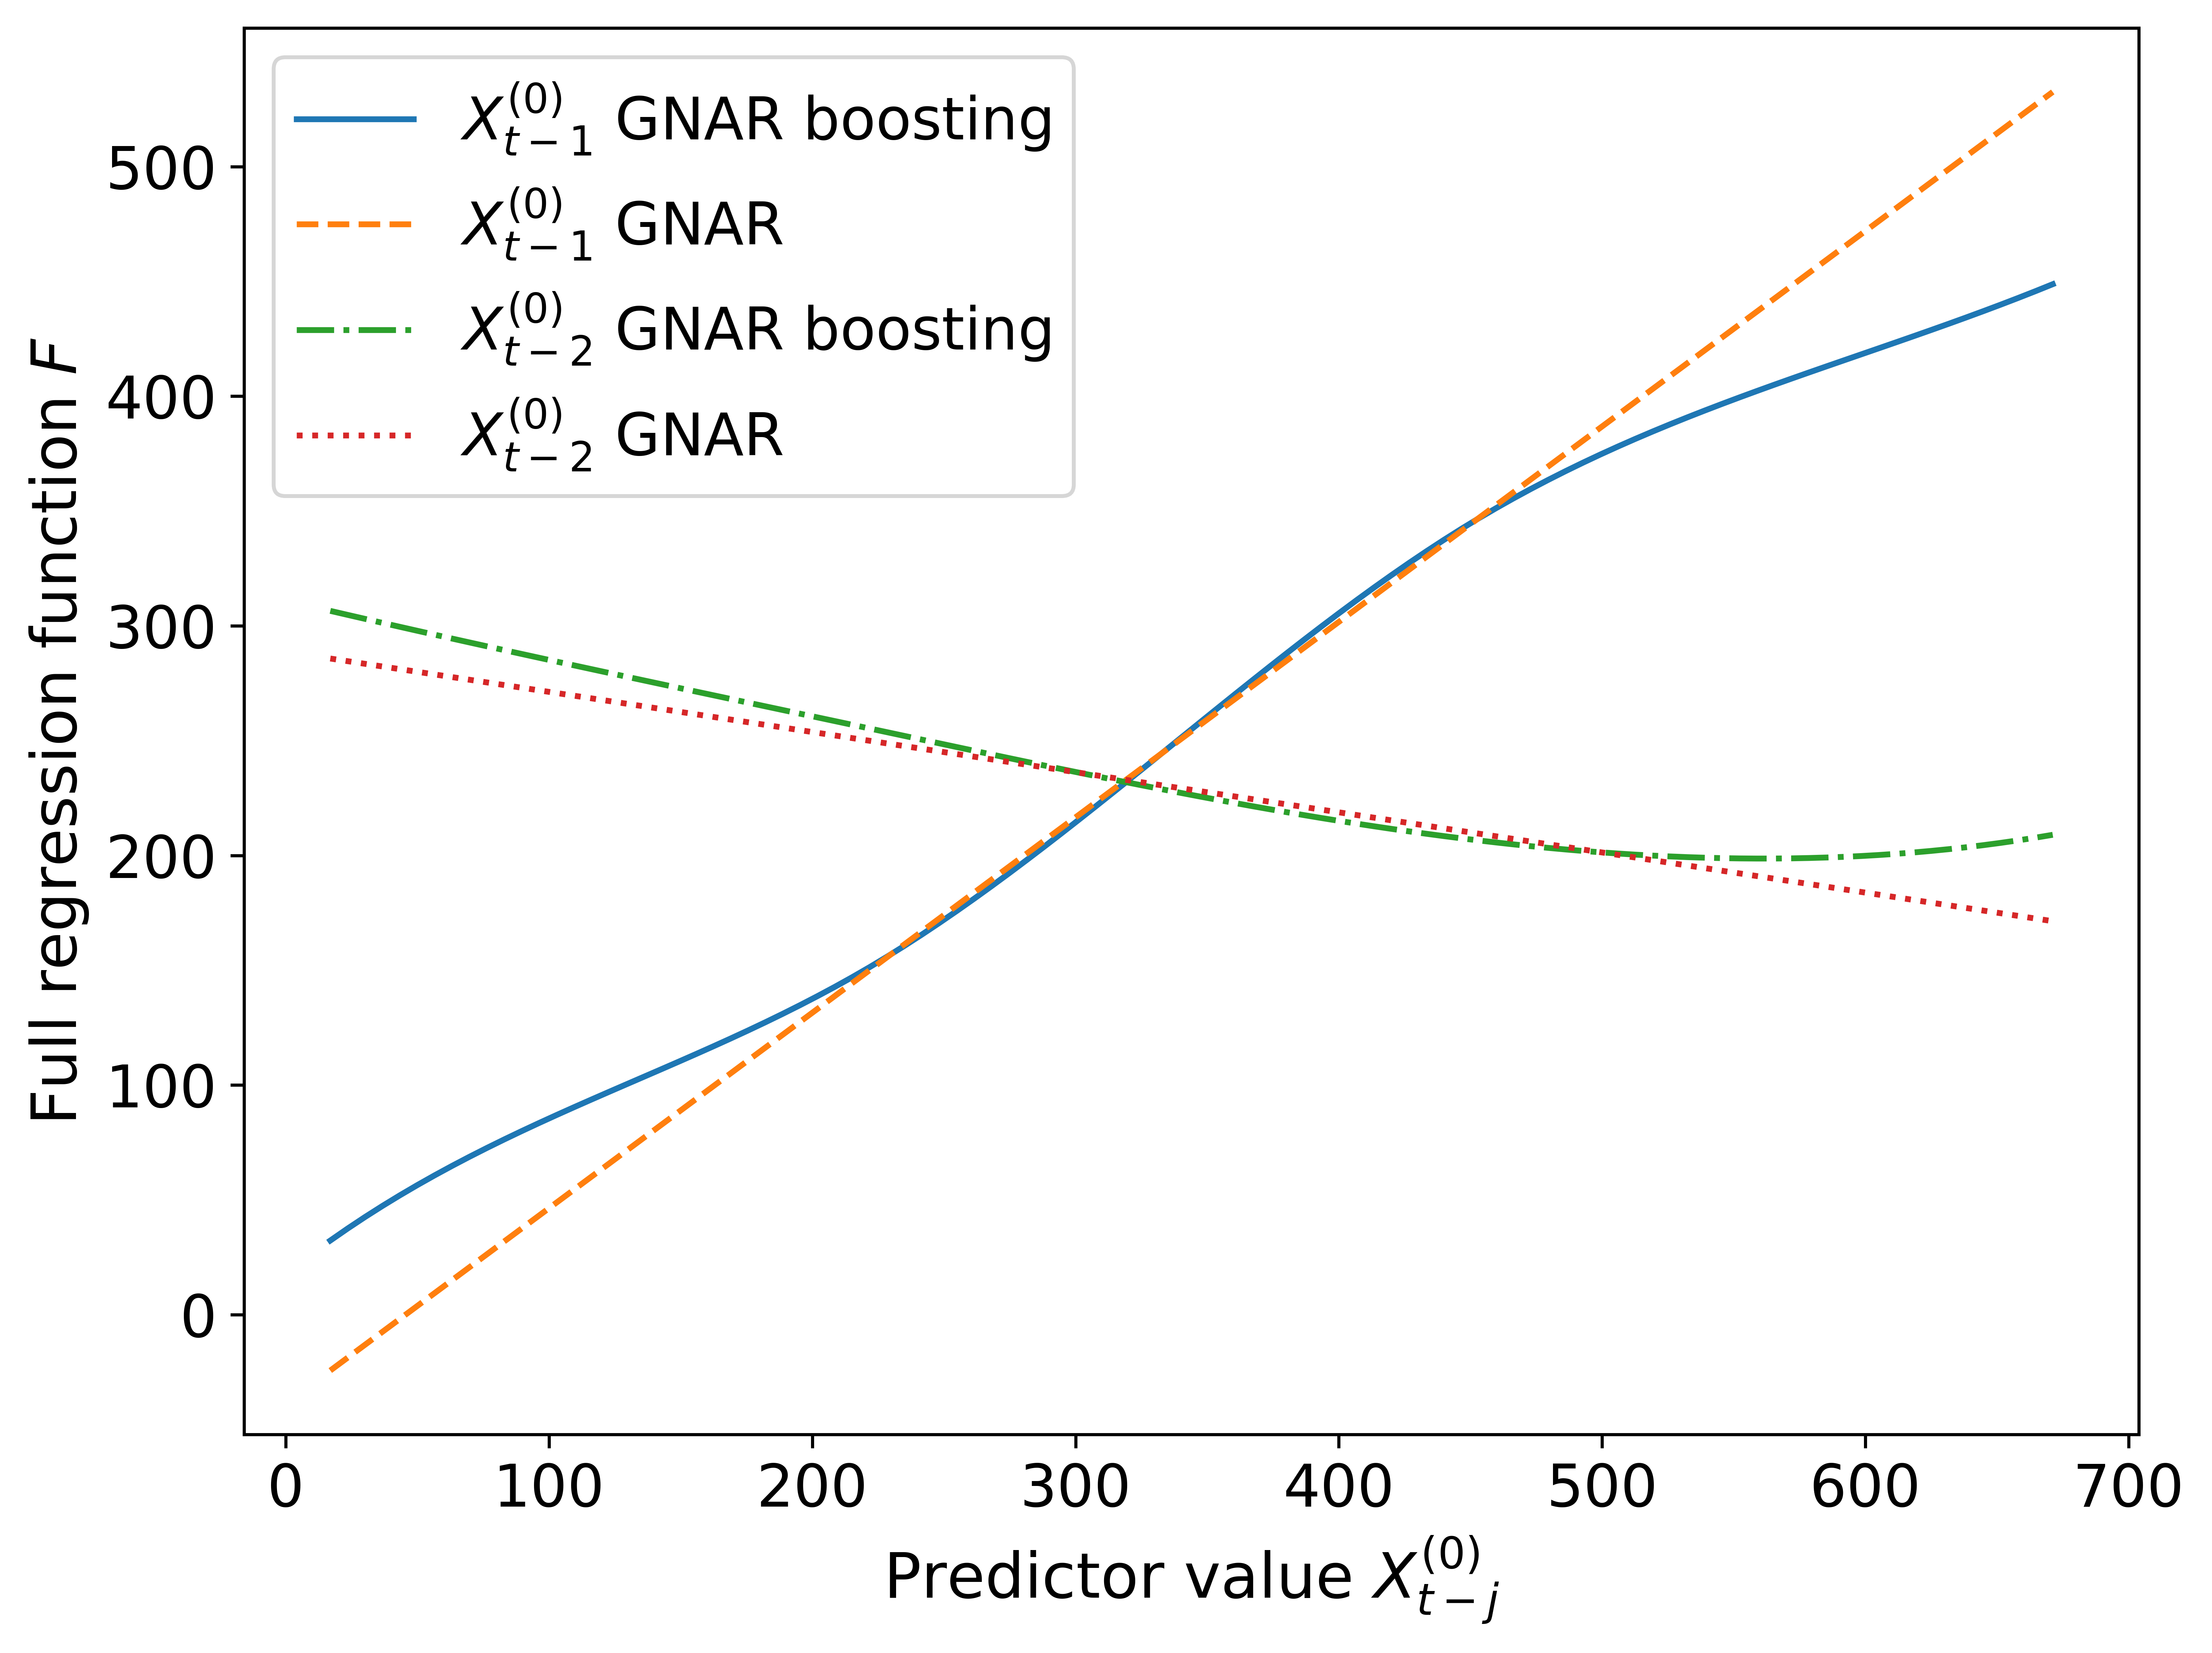

In [54]:
X_mean = np.mean(gnarb.gnars[0].X,axis=0)
X_mean[6:] = 0
x = np.quantile(gnarb.gnars[0].X[:,0],[0.05,0.95])
x = np.linspace(x[0],x[1],100)

plt.figure(figsize=(8,6),dpi=800)

for i in [0,3]:
    X = np.tile(x.reshape(-1,1),(1,6+42))
    X[:,:i] = X_mean[:i]
    X[:,i+1:] = X_mean[i+1:]

    y_b_1 = gnarb.evaluate(X,0)
    y_g_1 = X@gnarb.gnars[0].coefs

    if i == 0:
        plt.plot(x, y_b_1, label=rf"$X^{{(0)}}_{{t-{int(i/3+1)}}}$ GNAR boosting", linestyle="-")
        plt.plot(x, y_g_1, label=rf"$X^{{(0)}}_{{t-{int(i/3+1)}}}$ GNAR", linestyle="--")
    else:
        plt.plot(x, y_b_1, label=rf"$X^{{(0)}}_{{t-{int(i/3+1)}}}$ GNAR boosting", linestyle="-.")
        plt.plot(x, y_g_1, label=rf"$X^{{(0)}}_{{t-{int(i/3+1)}}}$ GNAR", linestyle=":")
plt.xlabel(r"Predictor value $X^{(0)}_{t-j}$", fontsize=16)
plt.ylabel(r"Full regression function $F$", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

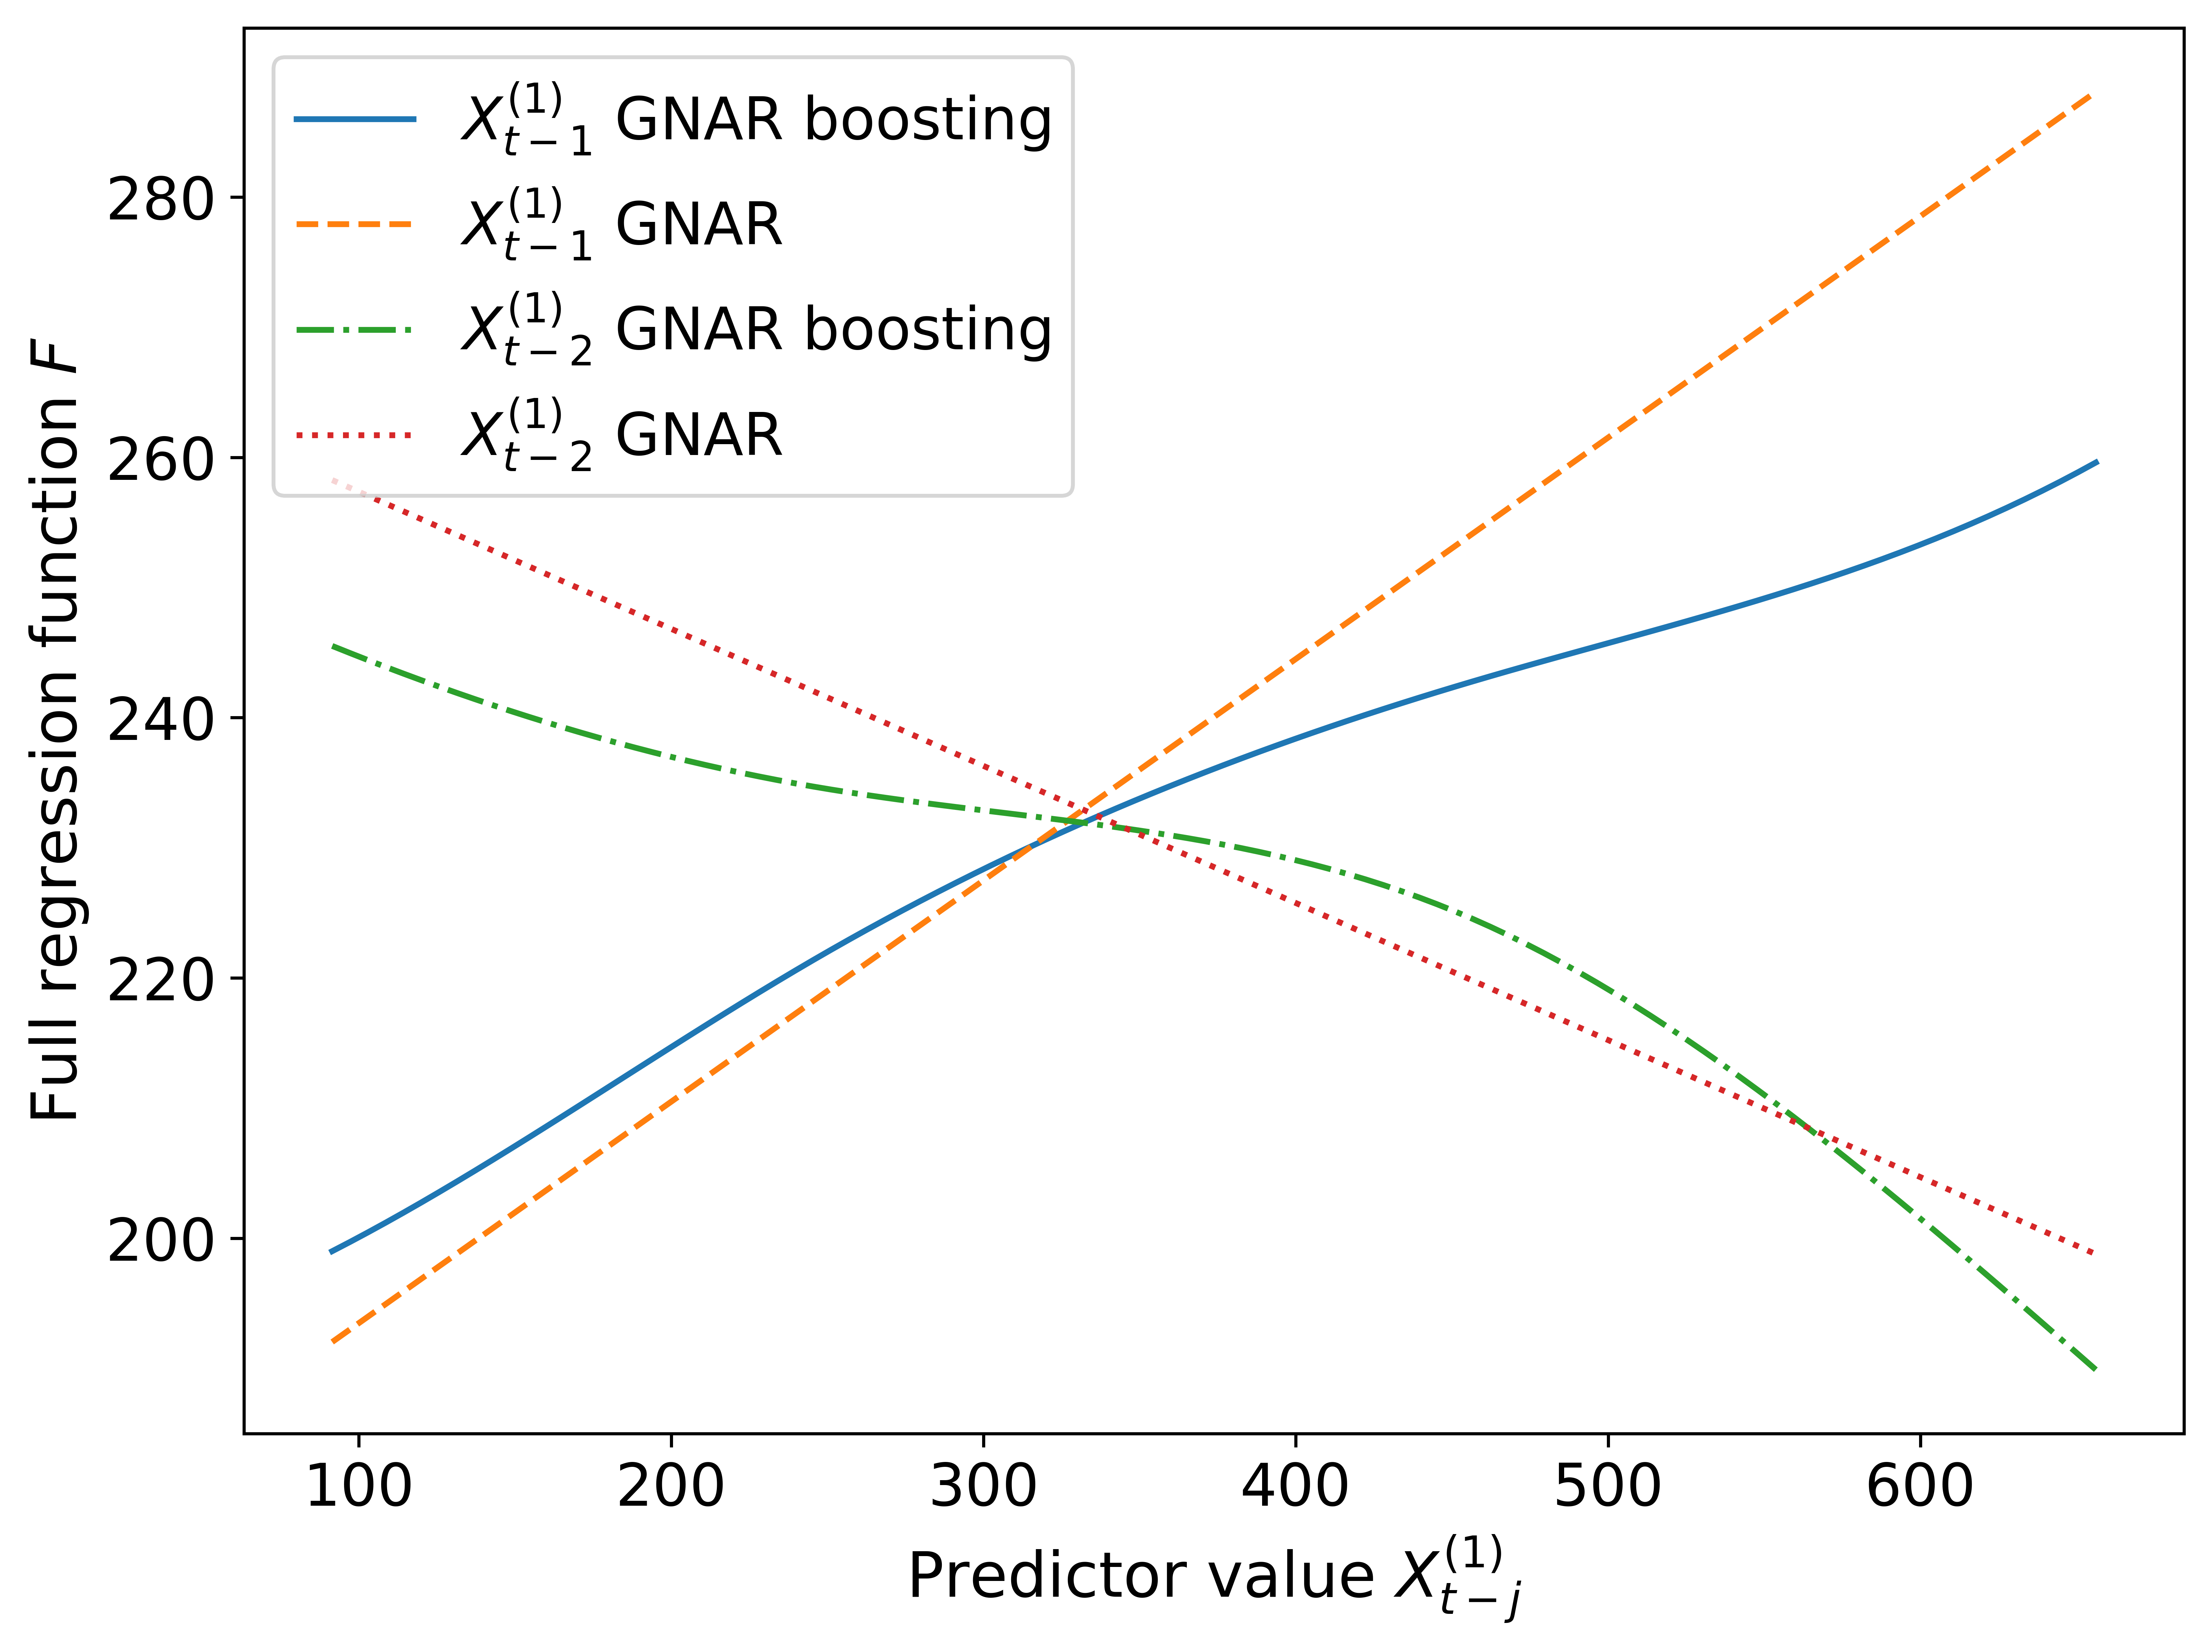

In [55]:
X_mean = np.mean(gnarb.gnars[0].X,axis=0)
X_mean[6:] = 0
x = np.quantile(gnarb.gnars[0].X[:,1],[0.05,0.95])
x = np.linspace(x[0],x[1],100)

plt.figure(figsize=(8,6),dpi=800)

for i in [1,4]:
    X = np.tile(x.reshape(-1,1),(1,6+42))
    X[:,:i] = X_mean[:i]
    X[:,i+1:] = X_mean[i+1:]

    y_b_1 = gnarb.evaluate(X,0)
    y_g_1 = X@gnarb.gnars[0].coefs

    if i == 1:
        plt.plot(x, y_b_1, label=rf"$X^{{(1)}}_{{t-{int(i/3+1)}}}$ GNAR boosting", linestyle="-")
        plt.plot(x, y_g_1, label=rf"$X^{{(1)}}_{{t-{int(i/3+1)}}}$ GNAR", linestyle="--")
    else:
        plt.plot(x, y_b_1, label=rf"$X^{{(1)}}_{{t-{int(i/3+1)}}}$ GNAR boosting", linestyle="-.")
        plt.plot(x, y_g_1, label=rf"$X^{{(1)}}_{{t-{int(i/3+1)}}}$ GNAR", linestyle=":")

plt.xlabel(r"Predictor value $X^{(1)}_{t-j}$", fontsize=16)
plt.ylabel(r"Full regression function $F$", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

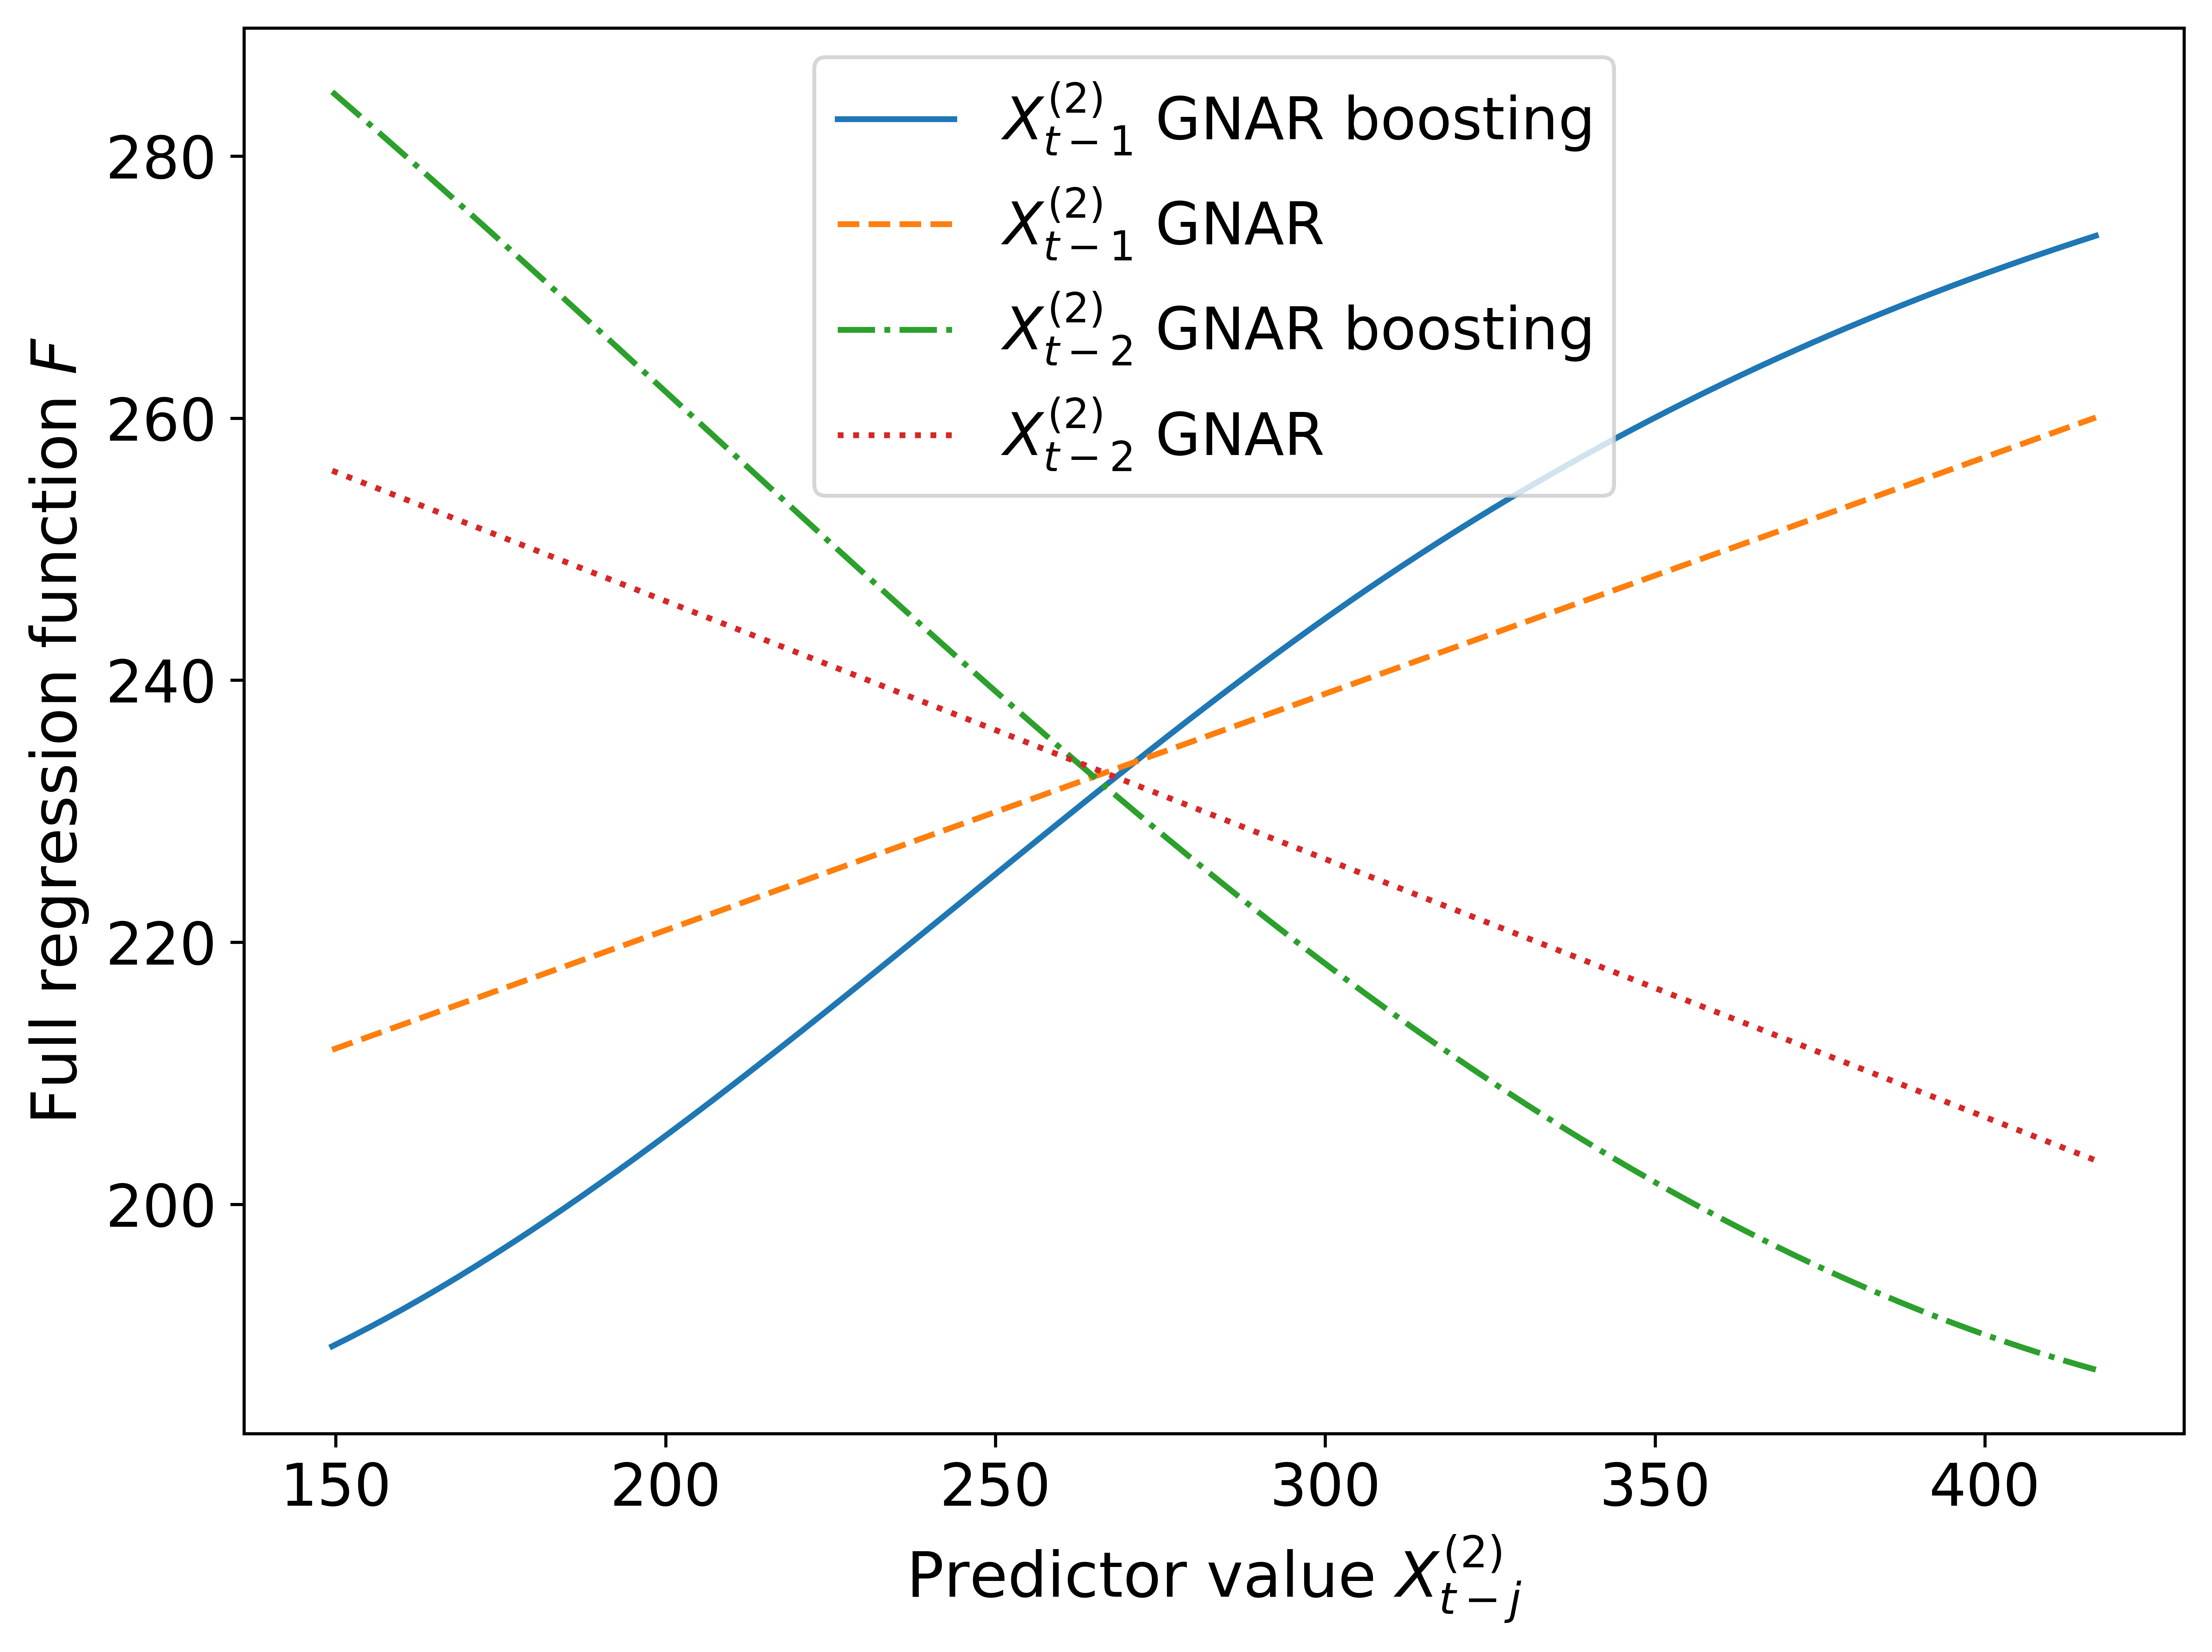

In [53]:
X_mean = np.mean(gnarb.gnars[0].X,axis=0)
X_mean[6:] = 0
x = np.quantile(gnarb.gnars[0].X[:,2],[0.05,0.95])
x = np.linspace(x[0],x[1],100)

plt.figure(figsize=(8,6),dpi=800)

for i in [2,5]:
    X = np.tile(x.reshape(-1,1),(1,6+42))
    X[:,:i] = X_mean[:i]
    X[:,i+1:] = X_mean[i+1:]

    y_b_1 = gnarb.evaluate(X,0)
    y_g_1 = X@gnarb.gnars[0].coefs

    if i == 2:
        plt.plot(x, y_b_1, label=rf"$X^{{(2)}}_{{t-{int(i/3+1)}}}$ GNAR boosting", linestyle="-")
        plt.plot(x, y_g_1, label=rf"$X^{{(2)}}_{{t-{int(i/3+1)}}}$ GNAR", linestyle="--")
    else:
        plt.plot(x, y_b_1, label=rf"$X^{{(2)}}_{{t-{int(i/3+1)}}}$ GNAR boosting", linestyle="-.")
        plt.plot(x, y_g_1, label=rf"$X^{{(2)}}_{{t-{int(i/3+1)}}}$ GNAR", linestyle=":")

plt.xlabel(r"Predictor value $X^{(2)}_{t-j}$", fontsize=16)
plt.ylabel(r"Full regression function $F$", fontsize=16)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(fontsize=15)

plt.tight_layout()
plt.show()

### Base coefs

In [35]:
gnarb.gnars[0].coefs

array([ 8.76547560e-01,  2.04619924e-01,  1.27795022e-01, -1.99456071e-01,
       -1.39913844e-01, -1.64643380e-01,  1.65554566e+01,  7.78034404e+01,
        2.42859608e+01,  7.91193813e+01,  4.52415317e+01,  7.95896492e+01,
        4.05430652e+01,  1.35577991e+02,  1.36441818e+02,  1.17931444e+02,
        1.32040923e+02,  1.38109936e+02,  1.21983354e+02, -3.39535689e+00,
       -7.33183917e+00,  1.23954862e+02,  1.37962746e+02,  1.24389041e+02,
       -8.12975191e-01, -5.96949317e+00, -4.28749230e+00, -1.10570162e+01,
        1.37472066e+02,  1.46058958e+02, -7.38875254e+00,  3.17895898e+01,
        3.34900533e+01,  1.56508742e+02,  1.34894341e+02,  1.37077073e+02,
        1.35779621e+02,  1.41426174e+01,  8.80485041e+01,  9.17812566e+01,
        1.17871365e+02,  1.48091602e+02,  1.62456341e+02,  1.22444303e+02,
        8.47874903e+01,  1.62192928e+02,  1.60813955e+02,  1.71127188e+02])